<a href="https://colab.research.google.com/github/Euugene0/11th-ML/blob/Week_10/Week10_%EB%B3%B5%EC%8A%B5%EA%B3%BC%EC%A0%9C_%EA%B9%80%EC%9C%A0%EC%A7%84.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 6장 차원 축소 part A

**범위:** 6.1 차원 축소 개요 · 6.2 PCA · 6.3 LDA  

- `scikit-learn` 내장 데이터만 사용하므로 별도 파일은 필요하지 않습니다.
- 제공된 시작 코드를 바탕으로 `TODO` 부분을 완성해주세요. 필요한 라이브러리나 변수는 추가하셔도 됩니다.
- 각 문항의 해석 질문은 실행 결과를 근거로 **2~3문장**으로 작성해주세요.


## 문제 1. Wine 데이터: 정보를 얼마나 유지하며 차원을 줄일 수 있을까?

Wine 데이터에는 **178개 샘플, 13개 수치 피처, 3개 클래스**가 있습니다.

**(a)** 13개 피처를 표준화한 뒤 PCA를 적용하세요. **누적 설명된 분산 비율이 처음으로 90% 이상**이 되는 최소 주성분 개수를 계산하고, 그때의 누적 설명된 분산 비율을 출력하세요.  
**(b)** (a)에서 찾은 개수만큼 주성분을 남겨 변환하고, 결과 배열의 모양을 출력하세요.  
**(c)** 주성분 개수가 2개일 때의 누적 설명된 분산 비율도 계산한 다음, (a)의 결과와 비교하여 **주성분을 많이 남길수록 얻는 점과 잃는 점**을 설명하세요.

힌트: `explained_variance_ratio_`, `np.cumsum`, `np.argmax`, `PCA(n_components=...)`

In [ ]:
import numpy as np
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

X, y = load_wine(return_X_y=True)
X_scaled = StandardScaler().fit_transform(X)

# (a) 누적 설명된 분산 비율이 90% 이상인 최소 차원
pca_all = PCA().fit(X_scaled)
cumulative_ratio = np.cumsum(pca_all.explained_variance_ratio_)
min_components = int(np.argmax(cumulative_ratio >= 0.90) + 1)
print(f"최소 주성분 개수: {min_components}")
print(f"누적 설명된 분산 비율: {cumulative_ratio[min_components - 1]:.6f} ({cumulative_ratio[min_components - 1] * 100:.2f}%)")

# (b) 해당 차원으로 변환
X_pca = PCA(n_components=min_components).fit_transform(X_scaled)
print("변환 후 shape:", X_pca.shape)

# (c) 2개 주성분일 때
print(f"2개 주성분의 누적 설명된 분산 비율: {cumulative_ratio[1]:.6f} ({cumulative_ratio[1] * 100:.2f}%)")

최소 주성분 개수: 8
누적 설명된 분산 비율: 0.920175 (92.02%)
변환 후 shape: (178, 8)
2개 주성분의 누적 설명된 분산 비율: 0.554063 (55.41%)


**해석 답안:**

누적 설명된 분산 비율이 처음으로 90% 이상이 되는 최소 주성분 개수는 8개이며, 이때 약 92.02%의 분산을 보존하고 변환 결과는 `(178, 8)`이다. 주성분 2개만 남기면 보존하는 분산은 약 55.41%이므로, 주성분을 더 많이 남길수록 원본 데이터의 변동을 더 많이 보존하고 재구성 오차를 줄일 수 있다. 반면 저장 공간과 후속 계산량이 늘고 2차원 시각화가 어려워지며, 여기서 보존되는 정보는 분산 기준이므로 분류에 필요한 정보의 보존과 반드시 일치하지는 않는다.

## 문제 2. 유방암 진단 데이터: PCA가 분류 성능에 미치는 영향

Breast Cancer Wisconsin 데이터에는 **569개 샘플, 30개 입력 피처, 2개 클래스**가 있습니다. 동일한 `LogisticRegression` 모델을 **원본 피처**와 **PCA로 5개 주성분으로 변환한 피처**에 각각 적용하려고 합니다.

**(a)** 원본 피처와 PCA 변환 피처에 대해 각각 `StandardScaler`가 포함된 `Pipeline`을 만들고, **5-Fold 층화 교차 검증**으로 평균 정확도를 구하세요. (두 모델 모두 동일한 `StratifiedKFold` 사용)  
**(b)** 두 모델의 평균 정확도 차이를 **퍼센트포인트(%p)** 단위로 출력하세요. (PCA 모델 − 원본 모델)  
**(c)** PCA 모델의 정확도가 낮아지거나 높아지더라도, **PCA가 반드시 분류 성능을 개선하는 방법은 아닌 이유**를 발표의 핵심 개념으로 설명하세요.

조건: `random_state=42`, `n_splits=5`, `shuffle=True`로 고정하세요. PCA는 **Pipeline 내부**에 배치합니다.

힌트: `make_pipeline`, `cross_val_score`, `StratifiedKFold`

In [ ]:
import numpy as np
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline

X, y = load_breast_cancer(return_X_y=True)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# (a) 각 fold의 학습 데이터에서만 표준화 및 PCA를 학습
original_model = make_pipeline(
    StandardScaler(), LogisticRegression(max_iter=1000, random_state=42)
)
pca_model = make_pipeline(
    StandardScaler(), PCA(n_components=5, random_state=42),
    LogisticRegression(max_iter=1000, random_state=42)
)
original_scores = cross_val_score(original_model, X, y, cv=cv, scoring="accuracy")
pca_scores = cross_val_score(pca_model, X, y, cv=cv, scoring="accuracy")
print("원본 모델 fold별 정확도:", original_scores)
print("PCA 모델 fold별 정확도:", pca_scores)
print(f"원본 평균 정확도: {original_scores.mean():.6f} ({original_scores.mean() * 100:.2f}%)")
print(f"PCA 평균 정확도: {pca_scores.mean():.6f} ({pca_scores.mean() * 100:.2f}%)")

# (b) 비율의 차이에 100을 곱하면 퍼센트포인트
accuracy_difference = (pca_scores.mean() - original_scores.mean()) * 100
print(f"평균 정확도 차이 (PCA - 원본): {accuracy_difference:+.4f}%p")

원본 모델 fold별 정확도: [0.97368421 0.94736842 0.96491228 0.99122807 0.99115044]
PCA 모델 fold별 정확도: [0.95614035 0.94736842 0.96491228 0.95614035 0.99115044]
원본 평균 정확도: 0.973669 (97.37%)
PCA 평균 정확도: 0.963142 (96.31%)
평균 정확도 차이 (PCA - 원본): -1.0526%p


**해석 답안:**

원본 모델의 평균 정확도는 약 97.37%, PCA 모델은 약 96.31%로, PCA 모델이 1.0526%p 낮게 나왔다. PCA는 클래스 레이블을 사용하지 않고 전체 데이터의 분산을 크게 보존하는 축을 선택하므로, 분산은 작지만 분류에 중요한 정보가 차원 축소 과정에서 사라질 수 있다. 따라서 잡음이나 중복 피처를 줄여 정확도가 좋아질 가능성도 있지만, 분류 성능 개선을 보장하지 않으므로 교차 검증으로 확인해야 한다.

## 문제 3. Wine 데이터: PCA와 LDA의 차원을 줄이는 기준 비교

문제 1의 Wine 데이터를 활용해 **13차원 → 2차원**으로 축소한 뒤, PCA와 LDA 결과를 비교하세요.

**(a)** `train_test_split(test_size=0.3, stratify=y, random_state=42)`로 학습·평가 데이터를 분리하고, 학습 데이터로만 `StandardScaler`를 학습해 두 데이터에 적용하세요. 그다음 **PCA(2개)**와 **LDA(2개)**를 각각 학습 데이터로 학습하여 학습·평가 데이터를 변환하세요. 결과 배열의 모양을 출력하세요. LDA에는 클래스 레이블을 입력해야 합니다.  
**(b)** 각각의 2차원 학습 데이터에 `LogisticRegression`을 학습하고, 평가 데이터 정확도를 출력하세요.  
**(c)** 두 방법이 서로 다른 결과를 내는 이유를 **사용하는 레이블과 축을 선택하는 기준**이라는 두 관점에서 설명하세요. 정확도가 높게 나온 방법이 모든 데이터에서 우월하다고 단정할 수 있는지도 덧붙이세요.

힌트: `LinearDiscriminantAnalysis(n_components=2)`, `fit_transform(X_train_scaled, y_train)`, `accuracy_score`

In [ ]:
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

X, y = load_wine(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=42
)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

pca = PCA(n_components=2, random_state=42)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

lda = LinearDiscriminantAnalysis(n_components=2)
X_train_lda = lda.fit_transform(X_train_scaled, y_train)
X_test_lda = lda.transform(X_test_scaled)
print("PCA 학습/평가 shape:", X_train_pca.shape, X_test_pca.shape)
print("LDA 학습/평가 shape:", X_train_lda.shape, X_test_lda.shape)

pca_clf = LogisticRegression(max_iter=1000, random_state=42)
lda_clf = LogisticRegression(max_iter=1000, random_state=42)
pca_clf.fit(X_train_pca, y_train)
lda_clf.fit(X_train_lda, y_train)
pca_accuracy = accuracy_score(y_test, pca_clf.predict(X_test_pca))
lda_accuracy = accuracy_score(y_test, lda_clf.predict(X_test_lda))
print(f"PCA 평가 정확도: {pca_accuracy:.6f} ({pca_accuracy * 100:.2f}%)")
print(f"LDA 평가 정확도: {lda_accuracy:.6f} ({lda_accuracy * 100:.2f}%)")

PCA 학습/평가 shape: (124, 2) (54, 2)
LDA 학습/평가 shape: (124, 2) (54, 2)
PCA 평가 정확도: 0.944444 (94.44%)
LDA 평가 정확도: 0.981481 (98.15%)


**해석 답안:**

두 방법의 변환 결과는 모두 학습 데이터 `(124, 2)`, 평가 데이터 `(54, 2)`이며, 이번 평가 정확도는 PCA 약 94.44%, LDA 약 98.15%이다. PCA는 레이블을 사용하지 않고 전체 분산을 최대한 보존하는 축을 선택하는 반면, LDA는 학습 데이터의 클래스 레이블을 사용해 클래스 내부 산포에 비해 클래스 사이 산포가 커지는 축을 선택하므로 결과가 달라진다. 이번 데이터 분할에서는 LDA가 더 높은 정확도를 보였지만 데이터 분포, 클래스 구조, 평가 표본에 따라 결과가 달라질 수 있으므로 모든 데이터에서 우월하다고 단정할 수 없다.

# **문제 4. SVD를 이용한 행렬 분해 및 복원**

## **4-1. 행렬 분해**

SVD를 이용하여 5x5 행렬 a를 분해 해주세요.

In [ ]:
import numpy as np
from numpy.linalg import svd

np.random.seed(10)
a = np.random.randn(5, 5)

U, Sigma, Vt = svd(a)

print('Origianl matrix a:\n', np.round(a, 3))
print('\nU matrix:\n', np.round(U, 3))
print('\nSigma matrix:\n', np.round(Sigma, 3))
print('\nV transpose matrix:\n', np.round(Vt, 3))

Origianl matrix a:
 [[ 1.332  0.715 -1.545 -0.008  0.621]
 [-0.72   0.266  0.109  0.004 -0.175]
 [ 0.433  1.203 -0.965  1.028  0.229]
 [ 0.445 -1.137  0.135  1.485 -1.08 ]
 [-1.978 -1.743  0.266  2.385  1.124]]

U matrix:
 [[-0.34   0.653 -0.057  0.53   0.416]
 [ 0.06  -0.106 -0.18  -0.506  0.835]
 [-0.116  0.668 -0.086 -0.655 -0.322]
 [ 0.291  0.183  0.923 -0.065  0.161]
 [ 0.884  0.286 -0.325  0.174  0.008]]

Sigma matrix:
 [4.077 2.543 1.952 1.107 0.3  ]

V transpose matrix:
 [[-0.531 -0.549  0.225  0.595  0.106]
 [ 0.295  0.211 -0.615  0.643  0.276]
 [ 0.548 -0.346  0.097  0.259 -0.71 ]
 [ 0.373 -0.698 -0.185 -0.327  0.483]
 [-0.437 -0.218 -0.726 -0.242 -0.419]]


## **4-2. 행렬 복원**

분해한 행렬을 복원해 주세요.

In [ ]:
# 특이값 벡터를 대각행렬로 변환
Sigma_mat = np.diag(Sigma)

# a = U @ Sigma_mat @ Vt
a_ = np.dot(np.dot(U, Sigma_mat), Vt)
print(np.round(a_, 3))
print("원본과 복원 행렬이 수치 오차 범위에서 같은가?:", np.allclose(a, a_))

[[ 1.332  0.715 -1.545 -0.008  0.621]
 [-0.72   0.266  0.109  0.004 -0.175]
 [ 0.433  1.203 -0.965  1.028  0.229]
 [ 0.445 -1.137  0.135  1.485 -1.08 ]
 [-1.978 -1.743  0.266  2.385  1.124]]
원본과 복원 행렬이 수치 오차 범위에서 같은가?: True


## **4-3. 위 코드에서 Sigma의 shape를 작성해 주세요.**

**답:** `Sigma.shape`는 `(5,)`이다. `numpy.linalg.svd`가 반환하는 `Sigma`는 특이값 5개를 담은 1차원 배열이며, `np.diag(Sigma)`로 만든 `Sigma_mat`의 shape는 `(5, 5)`이다.

# **문제 5. Truncated SVD를 이용한 차원 축소**
다음은 Wine 데이터셋에 Truncated SVD를 적용하여 13차원 데이터를 2차원으로 축소하는 코드입니다.

\## 답안 ## 에 알맞은 코드를 작성해 주세요.

## **5-1. 차원 축소**

2차원으로 축소해주세요.

축소 전 shape: (178, 13)
축소 후 shape: (178, 2)


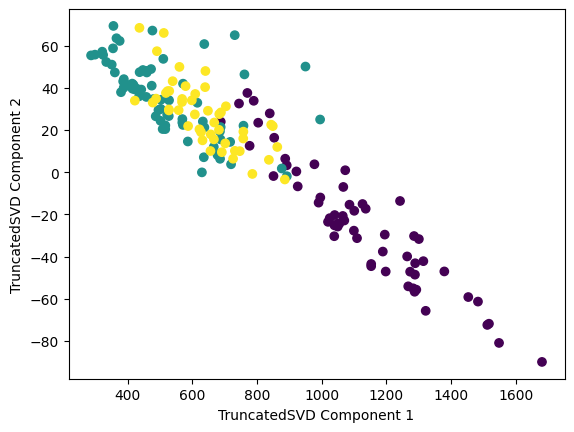

In [ ]:
from sklearn.decomposition import TruncatedSVD
from sklearn.datasets import load_wine
import matplotlib.pyplot as plt
%matplotlib inline

wine = load_wine()
wine_ftrs = wine.data

tsvd = TruncatedSVD(n_components=2, random_state=42)

tsvd.fit(wine_ftrs)
wine_tsvd = tsvd.transform(wine_ftrs)
print("축소 전 shape:", wine_ftrs.shape)
print("축소 후 shape:", wine_tsvd.shape)

# 시각화
plt.scatter(
    x=wine_tsvd[:, 0],
    y=wine_tsvd[:, 1],
    c=wine.target
)
plt.xlabel('TruncatedSVD Component 1')
plt.ylabel('TruncatedSVD Component 2')
plt.show()

# **문제 6. SVD와 Truncated SVD 비교**

#### **SVD와 Truncated SVD의 차이점을 사용되는 특이값의 개수와 행렬 복원 시 정보 손실여부를 중심으로 서술해 주세요.**

일반적인 SVD는 행렬의 모든 특이값과 대응하는 특이벡터를 구하며, 이를 모두 사용하면 원본 행렬을 부동소수점 연산 오차 범위에서 복원할 수 있다. Truncated SVD는 큰 특이값 k개와 대응하는 특이벡터만 사용하여 낮은 차원의 근사 행렬을 만들므로, 버린 특이값 중 0이 아닌 값이 있으면 복원할 때 정보 손실이 발생한다. 다만 k가 원본 행렬의 랭크 이상이면 모든 0이 아닌 특이값을 유지할 수 있으므로, 절단하더라도 이론적으로 정보 손실 없이 복원할 수 있다.

## 다른 차원의 축소 기법들 개념 복습

# **문제 7.**  
 Discord에 공유된 핸즈온 머신러닝pdf의 '8.6 다른 차원축소 기법들(p. 295 ~ 296)' 혹은 Week10 발표 ppt 속 '#06 다른 차원의 축소 기법들' 파트 내용을 참고해서 랜덤 투영 알고리즘, MDS, ISomap, t-SNE 중 하나의 차원 축소 기법을 골라 간단히 설명하세요.

**답: t-SNE**

t-SNE는 고차원 데이터에서 가까운 이웃 관계가 저차원에서도 유지되도록 데이터를 배치하는 비선형 차원 축소 기법이다. 고차원과 저차원에서 점 사이의 유사도를 확률로 표현하고 그 차이를 줄이는 방식으로 학습하며, 주로 2차원이나 3차원 시각화에 사용한다. 다만 전체적인 거리나 군집 사이의 간격은 왜곡될 수 있으므로, 그림에서 군집이 멀리 떨어져 있다는 이유만으로 원래 데이터에서도 그만큼 멀다고 해석해서는 안 된다.



## 여러가지 차원 축소 기법들 적용하기

# 문제 8. Dimensionality Reduction for Beginners
8-1)  `PCA`, `MDS`, `t-SNE`각각의 코드를 완성해 실행하세요.   
8-2) 세 기법의 차이를 간단히 서술하세요.

In [ ]:
#데이터 로딩하기

%matplotlib inline

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
import matplotlib.patches as mpatches
import seaborn as sns
from sklearn.datasets import load_breast_cancer #Loading the full DataSet From Sklearn Library

# Breast cancer dataset
cancer = load_breast_cancer()
(X_canc, y_canc) = load_breast_cancer(return_X_y = True)

In [ ]:
#시각화 함수 만들기

def plot_labelled_scatter(X, y, class_labels,s):
    num_labels = len(class_labels)
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1

    marker_array = ['o', '^', '*']
    color_array = ['#FFFF00', '#00AAFF', '#000000', '#FF00AA']
    cmap_bold = ListedColormap(color_array)
    bnorm = BoundaryNorm(np.arange(0, num_labels + 1, 1), ncolors=num_labels)
    plt.figure(figsize=s)

    plt.scatter(X[:, 0], X[:, 1], s=80, c=y, cmap=cmap_bold, norm = bnorm, alpha = 0.4, edgecolor='black', lw = 1)
    sp = plt.gca().spines
    sp['top'].set_visible(False)
    sp['right'].set_visible(False)

    plt.grid(which='both',color='lightslategrey',alpha=0.3)

    plt.xlim(x_min, x_max)
    plt.ylim(y_min, y_max)

    h = []
    for c in range(0, num_labels):
        h.append(mpatches.Patch(color=color_array[c], label=class_labels[c]))
    plt.legend(handles=h,fontsize=15,frameon=False)

8-1) `PCA`, `MDS`, `t-SNE` 코드 완성하기

PCA 코드 완성하기

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

canc_norm = StandardScaler().fit_transform(X_canc)
pca = PCA(n_components=2).fit(canc_norm)
canc_pca = pca.transform(canc_norm)

print('Number of Features in Breast Cancer DataSet Before PCA : {}\n\nNumber of Features in Breast Cancer DataSet After PCA : {}'
      .format(X_canc.shape[1], canc_pca.shape[1]))

Number of Features in Breast Cancer DataSet Before PCA : 30

Number of Features in Breast Cancer DataSet After PCA : 2


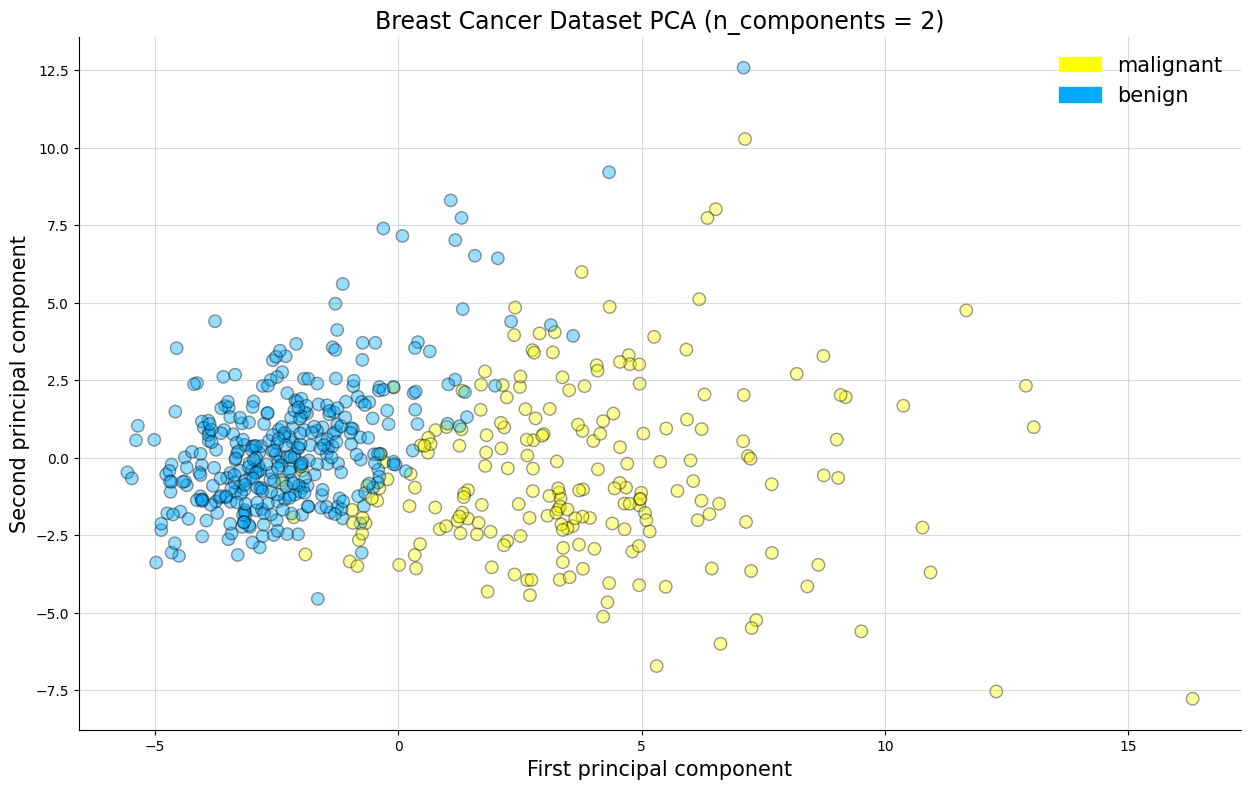

In [ ]:
#앞서 만든 함수 사용
plot_labelled_scatter(canc_pca, y_canc, ['malignant', 'benign'],(15,9))

#Labelling
plt.xlabel('First principal component',fontsize=15)
plt.ylabel('Second principal component',fontsize=15)
plt.title('Breast Cancer Dataset PCA (n_components = 2)',fontsize=17);

MDS 코드 완성하기

/opt/codex/runtimes/codex-primary-runtime/dependencies/python/lib/python3.12/site-packages/sklearn/manifold/_mds.py:754: FutureWarning: The default value of `init` will change from 'random' to 'classical_mds' in 1.10. To suppress this warning, provide some value of `init`.
  warnings.warn(
Number of Features in Breat Cancer DataSet Before MDS : 30

Number of Features in Breast Cancer DataSet After MDS : 2


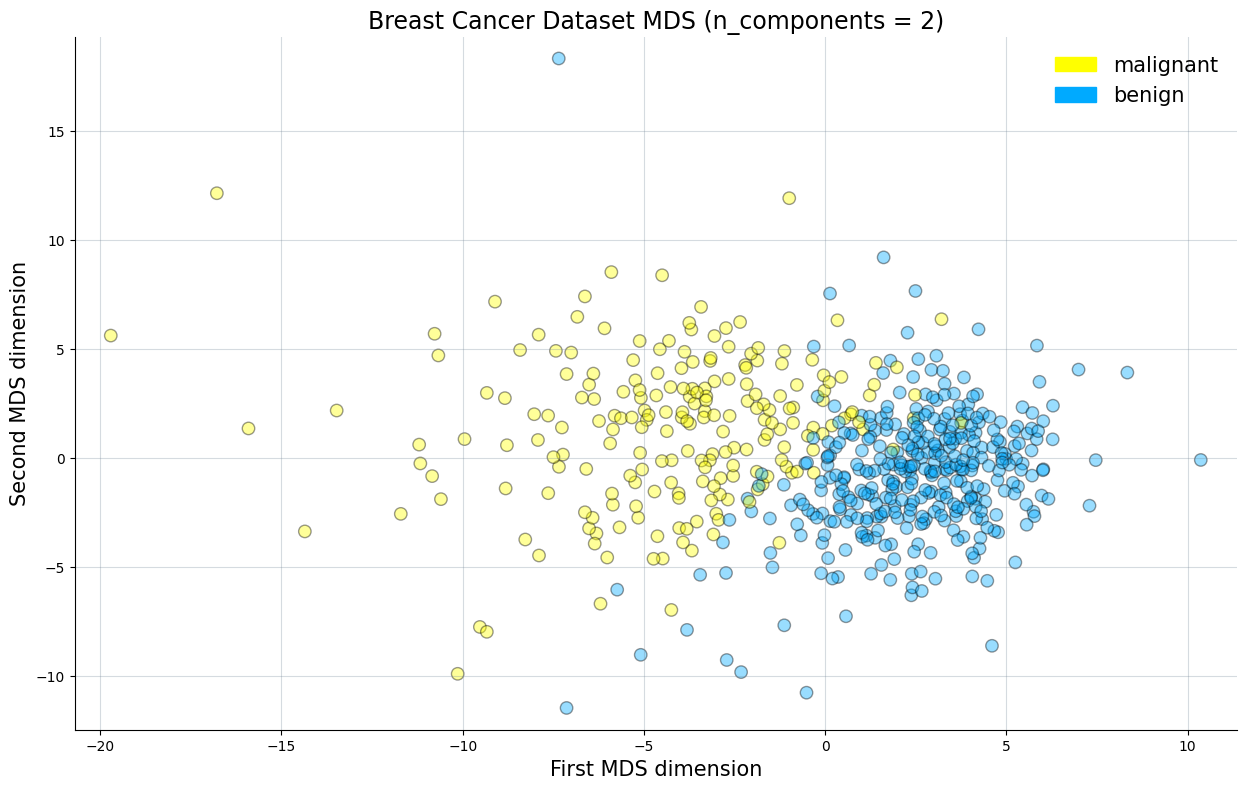

In [ ]:
from sklearn.manifold import MDS

mds = MDS(n_components=2, random_state=2, n_init=4)      #이때 n_components = 2,random_state = 2로 두기

canc_mds = mds.fit_transform(canc_norm)

print('Number of Features in Breat Cancer DataSet Before MDS : {}\n\nNumber of Features in Breast Cancer DataSet After MDS : {}'
      .format(X_canc.shape[1],canc_mds.shape[1]))

plot_labelled_scatter(canc_mds, y_canc, ['malignant', 'benign'],(15,9))

plt.xlabel('First MDS dimension',fontsize=15)
plt.ylabel('Second MDS dimension',fontsize=15)
plt.title('Breast Cancer Dataset MDS (n_components = 2)',fontsize=17);

t-SNE 코드 완성하기

Number of Features in Breat Cancer DataSet Before T-SNE : 30

Number of Features in Breast Cancer DataSet After T-SNE : 2


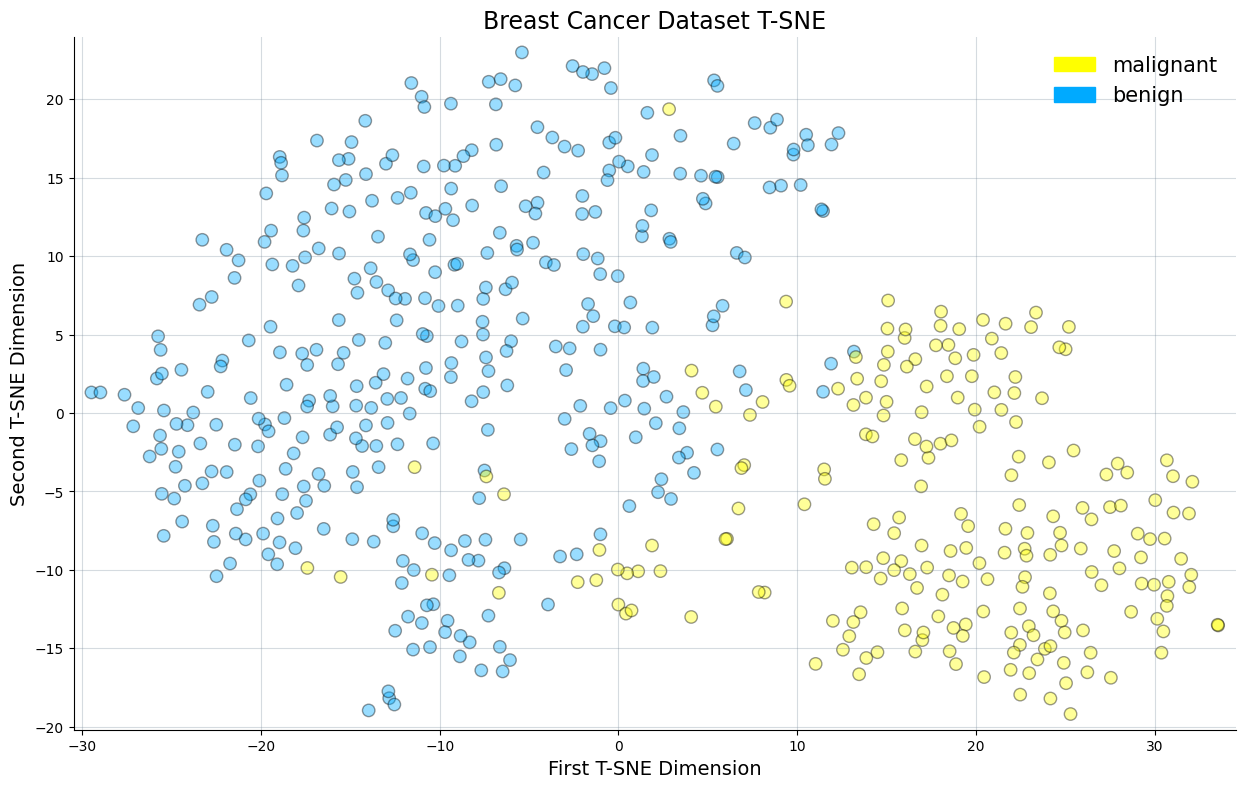

In [ ]:
from sklearn.manifold import TSNE

tsne = TSNE(n_components=2, random_state=42)     #이때 random_state = 42로 두기

canc_tsne = tsne.fit_transform(canc_norm)

print('Number of Features in Breat Cancer DataSet Before T-SNE : {}\n\nNumber of Features in Breast Cancer DataSet After T-SNE : {}'
      .format(X_canc.shape[1],canc_tsne.shape[1]))

plot_labelled_scatter(canc_tsne, y_canc, ['malignant', 'benign'],(15,9))

plt.xlabel('First T-SNE Dimension',fontsize=14)
plt.ylabel('Second T-SNE Dimension',fontsize=14)
plt.title('Breast Cancer Dataset T-SNE',fontsize=17);

8-2) 세 기법의 차이를 간단히 서술하세요.

**답:** PCA는 데이터의 분산을 최대한 보존하는 서로 직교하는 축을 구해 선형으로 차원을 줄이는 방법이며, 학습한 축으로 새로운 데이터도 변환할 수 있다. MDS는 원래 데이터에서 점 사이의 거리 관계가 저차원에서도 최대한 유지되도록 배치하는 방법이다. t-SNE는 특히 가까운 이웃 관계를 보존하는 비선형 기법으로 시각화에 유용하지만 전체적인 거리나 군집 사이 간격을 그대로 해석하기 어렵고, 세 방법 모두 여기서는 레이블 없이 차원을 줄이며 클래스 레이블은 결과를 색칠할 때만 사용한다.